<center>
<h1> TP-Projet d'optimisation numérique </h1>
<h1> Algorithme de Newton </h1>
</center>

## Implémentation 
 
1. Coder l’algorithme de Newton dans le fichier `src/newton.jl` en respectant la spécification donnée dans ce même fichier ;
2. Exécuter les tests ci-dessous et vérifier qu'ils passent.

Pour les tests, nous avons défini les fonctions suivantes $f_1 \colon \mathbb{R}^3 \to \mathbb{R}$
et $f_2 \colon \mathbb{R}^2 \to \mathbb{R}$.

$$
    f_{1}(x_1, x_2, x_3) = 2 (x_1 +x_2 + x_3 -3)^2 + (x_1-x_2)^2 + (x_2 - x_3)^2
$$
et
$$
    f_{2}(x_1,x_2) = 100(x_2-x_1^2)^2 + (1-x_1)^2.
$$

**Remarque.** On peut retrouver ces fonctions dans le fichier `test/fonctions_de_tests.jl`.

In [1]:
include("../src/newton.jl")         # votre algorithme de Newton
include("../test/tester_newton.jl") # la fonction pour tester votre algorithme de Newton
# using Pkg
# Pkg.add("Plots")
#
afficher = true # si true, alors affiche les résultats des algorithmes

#
tester_newton(newton, afficher); # tester l'algorithme de Newton

Affichage des résultats des algorithmes : true

-------------------------------------------------------------------------
Résultats de : newton appliqué à f1:
  * x0       = [1, 1, 1]
  * x_sol    = [1, 1, 1]
  * f(x_sol) = 0
  * nb_iters = 0
  * flag     = 0
  * solution = [1, 1, 1]
-------------------------------------------------------------------------
Résultats de : newton appliqué à f1:
  * x0       = [1, 0, 0]
  * x_sol    = [1.0, 1.0, 0.9999999999999999]
  * f(x_sol) = 1.232595164407831e-32
  * nb_iters = 1
  * flag     = 0
  * solution = [1, 1, 1]
-------------------------------------------------------------------------
Résultats de : newton appliqué à f1:
  * x0       = [10.0, 3.0, -2.2]
  * x_sol    = [1.0, 0.9999999999999996, 0.9999999999999987]
  * f(x_sol) = 7.296963373294359e-30
  * nb_iters = 1
  * flag     = 0
  * solution = [1, 1, 1]
-------------------------------------------------------------------------
Résultats de : newton appliqué à f2:
  * x0       = [-1.2, 1.0

In [1]:
include("../src/newton.jl") # votre algorithme de Newton
include("../test/fonctions_de_tests.jl") # pour avoir la fonction d'affichage des résultats

# Fonction f0
# -----------
f0(x)      =  sin(x)
grad_f0(x) =  cos(x) # la gradient de la fonction f0
hess_f0(x) = -sin(x) # la hessienne de la fonction f0
solution   = -pi/2

x0 = solution
x_sol, f_sol, flag, nb_iters = newton(f0, grad_f0, hess_f0, x0)
afficher_resultats("Newton", "f0", x0, x_sol, f_sol, flag, nb_iters, solution)

x0 = -pi/2+0.5
x_sol, f_sol, flag, nb_iters = newton(f0, grad_f0, hess_f0, x0)
afficher_resultats("Newton", "f0", x0, x_sol, f_sol, flag, nb_iters, solution)

x0 = pi/2
x_sol, f_sol, flag, nb_iters = newton(f0, grad_f0, hess_f0, x0)
afficher_resultats("Newton", "f0", x0, x_sol, f_sol, flag, nb_iters, solution)


-------------------------------------------------------------------------
Résultats de : Newton appliqué à f0:
  * x0       = -1.5707963267948966
  * x_sol    = -1.5707963267948966
  * f(x_sol) = -1.0
  * nb_iters = 0
  * flag     = 0
  * solution = -1.5707963267948966
-------------------------------------------------------------------------
Résultats de : Newton appliqué à f0:
  * x0       = -1.0707963267948966
  * x_sol    = -1.5707963267949088
  * f(x_sol) = -1.0
  * nb_iters = 3
  * flag     = 0
  * solution = -1.5707963267948966
-------------------------------------------------------------------------
Résultats de : Newton appliqué à f0:
  * x0       = 1.5707963267948966
  * x_sol    = 1.5707963267948966
  * f(x_sol) = 1.0
  * nb_iters = 0
  * flag     = 0
  * solution = -1.5707963267948966


## Interprétation 

**1. Justifier les résultats obtenus pour l'exemple $f_0$ ci-dessus.**

-> Pour $x_0 = -\pi/2$ *i.e* la solution exacte, l'algorithme converge sans itérer et trouve le minimum ($-1$) directement, comme attendu. Accessoirement, il s'agit de la première condition d'arrêt de notre algorithme.

-> Pour $x_0 = -\pi/2 + 0.5$, malgré le décalage de $+0.5$, la direction de Newton est suffisamment proche localement pour que l'algorithme arrive à converger vers le bon résultat au bout de 3 itérations.

-> Pour $x_0 = \pi/2$, on est encore sur un point critique et donc sur une condition d'arrêt qui fait que l'algorithme s'arrête sans itérer, sans pour autant trouver la bonne solution. Notons que le flag levé reste 0.

**2. Justifier que l’algorithme implémenté converge en une itération pour $f_{1}$.**

->La fonction $f_1$ est une forme quadratique. Or, sa matrice hessienne est constante ($\nabla^2 f_1(x) = \begin{pmatrix}
6 & 2 & 4 \\
2 & 8 & 2 \\
4 & 2 & 6 
\end{pmatrix}  $). Elle est définie positive donc strictement convexe. Ainsi, en calculant le point suivant avec la direction de Newton, on arrive à la solution en une seule itération.

**3. Justifier que l’algorithme puisse ne pas converger pour $f_{2}$ avec certains points initiaux.**

-> L'algorithme de Newton converge localement. Ainsi, si le point initial n'est pas pris suffisamment près de la solution, la direction de Newton peut ne pas être la bonne et donc faire diverger l'algorithme.

4. Proposez une stratégie permettant d’assurer la convergence de la méthode de Newton indépendamment du point initial. Décrivez l’idée sous-jacente et expliquez en quoi elle modifie ou sécurise l’itération de Newton standard.

-> Il s'agit de la méthode des régions de confiance proposée dans la suite du sujet, qui permet d'assurer la convergence globale de la méthode de Newton:
    
Cela se fait en définissant une région de confiance $R_k = \{x_k + s \text{ ,tq } \|s\| \leq \Delta_k \}$ autour du point courant $x_k$, dans laquelle on peut approcher la fonction objectif par une fonction modèle $m_k(s)$ dont la minismisation est plus "simple". Le résultat $s_k$ de cette minimisation est la direction supposée de l'itéré suivant, mais il faut d'abord vérifier qu'elle ne cause pas une trop grande différence entre la fonction modèle et la fonction objectif réelle. Si c'est le cas, on réduit le rayon $\Delta_k$ de la région de confiance et on recommence à minimiser jusqu'à obtenir une différence acceptable. 
    
Cette méthode sécurise alors l'itération de Newton standard en prenant en compte toutes les directions.

5. Tracez l’évolution de la norme du gradient en fonction du numéro d’itération pour $f_2$. Identifiez et expliquez l’itération à partir de laquelle la méthode entre dans le régime de convergence quadratique.

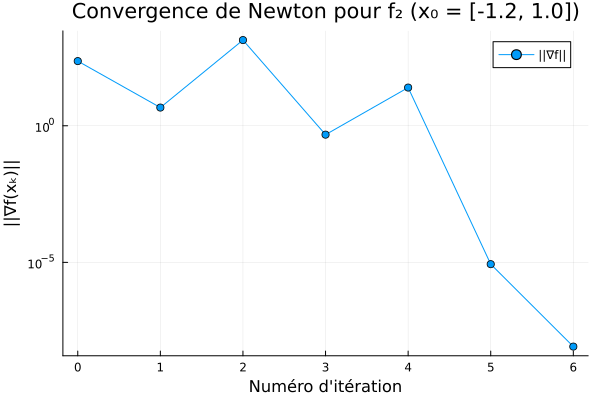


Point initial x₀ = [-1.2, 1.0]
Nombre d'itérations : 6
Flag : 0

Normes du gradient :
  Itération 0: ||∇f|| = 232.86768775422664
  Itération 1: ||∇f|| = 4.639426214066757
  Itération 2: ||∇f|| = 1370.78984944589
  Itération 3: ||∇f|| = 0.4731103791063711
  Itération 4: ||∇f|| = 25.02744559673527
  Itération 5: ||∇f|| = 8.608633530554741e-6
  Itération 6: ||∇f|| = 8.285705791275366e-9

Point initial x₀ = [10.0, 0.0]
Nombre d'itérations : 3
Flag : 0

Normes du gradient :
  Itération 0: ||∇f|| = 400517.6654331242
  Itération 1: ||∇f|| = 17.99990992761418
  Itération 2: ||∇f|| = 36228.30579297283
  Itération 3: ||∇f|| = 0.0007288161216332705


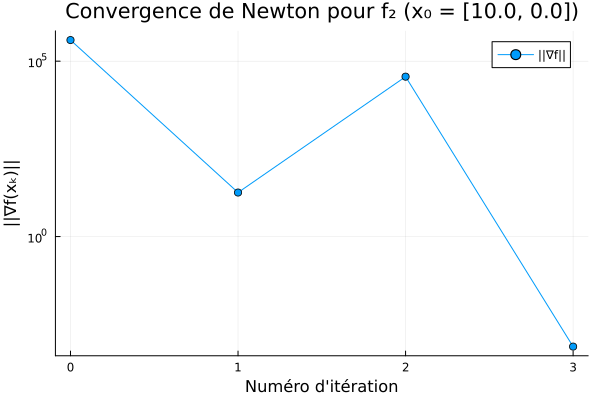

SingularException: SingularException(2)

In [ ]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots
using Plots

include("../test/fonctions_de_tests.jl")

x0_list = [pts1.x021, pts1.x022, pts1.x023]

for (i, x0) in enumerate(x0_list)
    # Exécuter Newton et récupérer les itérés
    x_sol, f_sol, flag, nb_iters, xs = newton(fct2, grad_fct2, hess_fct2, x0)
    
    grad_norms = [norm(grad_fct2(x)) for x in xs]
    
    # Tracer
    plot(0:nb_iters, grad_norms, 
         yscale=:log10,
         marker=:circle,
         xlabel="Numéro d'itération",
         ylabel="||∇f(xₖ)||",
         title="Convergence de Newton pour f₂ (x₀ = $x0)",
         label="||∇f||",
         legend=:topright,
         grid=true)
    
    # Afficher les résultats
    println("\nPoint initial x₀ = $x0")
    println("Nombre d'itérations : $nb_iters")
    println("Flag : $flag")
    println("\nNormes du gradient :")
    for (k, gn) in enumerate(grad_norms)
        println("  Itération $(k-1): ||∇f|| = $gn")
    end
    
    display(current())
end

x0 = pts1.x021
x_sol, f_sol, flag, nb_iters, xs = newton(fct2, grad_fct2, hess_fct2, x0)

grad_norms = [norm(grad_fct2(x)) for x in xs]

println("\nAnalyse du taux de convergence:")
println("Itération | ||∇f|| | Ratio ||∇f_{k+1}|| / ||∇f_k||²")
println("-" ^ 60)

for k in 1:length(grad_norms)-1
    if grad_norms[k] > 1e-12
        ratio = grad_norms[k+1] / (grad_norms[k]^2)
        println("$k | $(grad_norms[k]) | $ratio")
    end
end

plot(0:nb_iters, grad_norms, 
     yscale=:log10,
     marker=:circle,
     xlabel="Numéro d'itération",
     ylabel="||∇f(xₖ)|| (échelle log)",
     title="Convergence quadratique de Newton pour f₂",
     label="||∇f||",
     legend=:topright,
     linewidth=2,
     markersize=6)


6. Discutez de l’importance du fait que la matrice hessienne soit inversible à chaque itération. Avez-vous rencontré des exemples où cette condition n’était pas satisfaite ? Si oui, décrivez le comportement observé et son impact sur la convergence.

-> Comme la définition de la direction de Newton dépend de l'inverse de la hessienne, elle doit obligatoirement être inversible à chaque itéraion afin de modifier notre itéré.

Cette condition a été rencontrée avec $f_2$ pour le point $x_023 = \begin{pmatrix}
0 \\
1/200 + 1/10^18
\end{pmatrix}$. C'est d'ailleurs pour cela que dans la cellule précédente, on obtient une "SingularException". L'algorithme ne converge pas et on dépasse le nombre maximal d'itérations.

7. Expliquez pourquoi il est essentiel que la matrice hessienne soit localement définie positive au point optimal lors de l’application de la méthode de Newton pour la minimisation. Reliez cette propriété à la nature du point stationnaire et à la direction de descente.

-> À partir de l'epxlication du sujet, on comprend que la définie positivité de la hessienne est essentielle pour plusieurs choses: Tout d'abord, parce que $f$ est remplacé par son développement de Taylor à l'ordre 2, dont le minimum n'existe et est unique que si la hessienne est définie positive. Aussi, elle définit la condition nécessaire du second ordre; En effet, si la hessienne est définie positive au point optimal, cela signifie que ce point est un minimum local (et non un maximum ou un point selle). C'est le cas car cela implique la stricte convexité de la fonction autour du point optimal. Enfin, notre méthode pour trouver l'itéré suivant et donc la direction de la descente dépend de l'inverse de la hessienne qui doit donc être définie positive pour que la direction soit une direction de descente.

**Remarque.** Vous pouvez mettre `affiche=true` dans les tests de l'algorithme de Newton pour
vous aider.